In [61]:
from clustering.cluster import *
from data_access.DataProvider import *
import numpy as np

data_provider = DataProvider()
max_count = 100
rows = data_provider.get_articles('PL', max_count)

corpus = [row[0] for row in rows[0:max_count]] + [row[1] for row in rows[0:max_count]]
results = [row[2] for row in rows[0:max_count]]


In [68]:
from data_access.DataProvider import *

db = DataInput()
rows = db.get_articles()


corpus = [row[2] for row in rows]

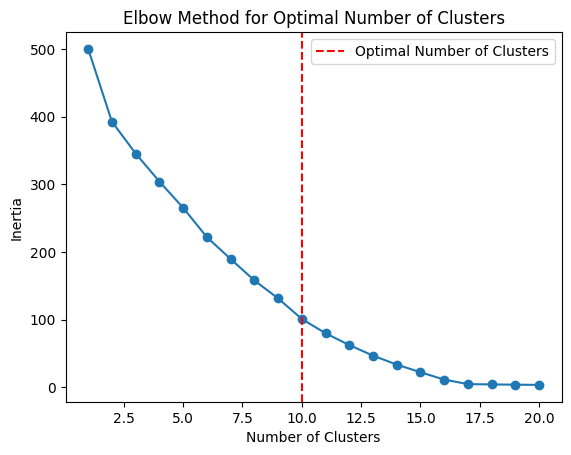

10
Document: As a result of Tomas Soucek's controversial opening goal, West Ham emerged victorious 2-0 at the Emirates, claiming their first home loss of the season in the Premier League. West Ham have won their first game at the venue since 2015.
A 13-minute West Ham lead that was against the flow of play was ruled to be still in play by VAR, preventing Mikel Arteta's squad from regaining the lead over Liverpool. The decision rendered the ball still in play at the time.
The incoming team was unable to contain the deranged cross from Emerson, which was promptly returned across the goal by Jarrod Bowen for Soucek to head into the vacant net.

Bowen assisted a teammate in scoring his fifth league goal of the season. Referee Michael Oliver was delayed for three minutes before VAR was able to confirm the goal after failing to find conclusive evidence that it had gone out.
Although West Ham was held in check for significant portions of the match, they secured a memorable victory at the 55-m

In [72]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from kneed import KneeLocator
from models.model import EnglishBertModel

model = EnglishBertModel()
# Encode the entire corpus into embeddings
matrix = model.Transform2(corpus)

# Determine the optimal number of clusters using the elbow method
inertia_values = []
max_clusters = 20  # You can adjust the maximum number of clusters

for i in range(1, max_clusters + 1):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)  # Set n_init explicitly
    kmeans.fit(matrix)
    inertia_values.append(kmeans.inertia_)

# Use the KneeLocator to find the "elbow" point automatically
knee_locator = KneeLocator(range(1, max_clusters + 1), inertia_values, curve="convex", direction="decreasing")
optimal_num_clusters = knee_locator.elbow

# Plot the elbow method with the identified optimal number of clusters
plt.plot(range(1, max_clusters + 1), inertia_values, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.axvline(optimal_num_clusters, color='red', linestyle='--', label='Optimal Number of Clusters')
plt.legend()
plt.show()

# Perform k-means clustering with the optimal number of clusters
kmeans = KMeans(n_clusters=optimal_num_clusters, random_state=42, n_init=10)  # Set n_init explicitly
cluster_assignments = kmeans.fit_predict(matrix)
print(optimal_num_clusters)
# Print the cluster assignments for each document
for res, cluster in zip(corpus, cluster_assignments):
    print(f"Document: {res}\nCluster: {cluster}\n")


In [71]:
from pipelines import *

factory = ReportFactory()
factory.generate_clustering_report(corpus, 'EN', 'results_english.xlsx')


In [12]:
from sklearn.metrics import silhouette_score
silhouette_avg = silhouette_score(matrix, cluster_assignments)
silhouette_avg

0.3535401

'Trwa 517. dzień rosyjskiej inwazji na Ukrainę. — Nasza kontrofensywa przebiega wolniej, niż zakładano, ale rozwija się zgodnie z planem — powiedział minister obrony Ukrainy Ołeksij Reznikow. W jego ocenie czynnikami spowalniającymi ataki Ukraińców są: brak amunicji, szczególnie artyleryjskiej, samych systemów artyleryjskich oraz problem obrony powietrznej. Zapraszamy do śledzenia relacji na żywo.'

In [14]:
from sklearn.metrics import calinski_harabasz_score

ch_score = calinski_harabasz_score(matrix, cluster_assignments)
ch_score

1577.2779265070876

In [48]:
from clustering.cluster import *
from data_access.DataProvider import *
import numpy as np

data_provider = DataProvider()
max_count = 10
rows = data_provider.get_articles('SL', max_count)

corpus = [[row[0],row[1]] for row in rows[0:max_count]]
results = [row[2] for row in rows[0:max_count]]


In [64]:
from clustering.cluster import *
from data_access.DataProvider import *
import numpy as np

data_provider = DataProvider()
max_count = 50
rows = data_provider.get_articles('PL', max_count)

corpus = [row[0] for row in rows[0:max_count]] + [row[1] for row in rows[0:max_count]]
results = [row[2] for row in rows[0:max_count]]


In [65]:
from models import *

model = PolishBertModel()



In [66]:
import timeit
num_iterations = 1
execution_times = timeit.repeat(lambda: model.Transform2(corpus), number=num_iterations)

# Print statistics
print(f"Number of iterations: {num_iterations}")
print(f"Minimum execution time: {min(execution_times):.2f} seconds")
print(f"Maximum execution time: {max(execution_times):.2f} seconds")
print(f"Average execution time: {sum(execution_times) / len(execution_times):.2f} seconds")

Number of iterations: 1
Minimum execution time: 12.23 seconds
Maximum execution time: 13.74 seconds
Average execution time: 12.96 seconds
